# 02 — EDA de modelagem

Análise exploratória da base de modelagem (`data/processed/base_modelagem.parquet`, 5.232 municípios), orientada às decisões de modelagem. Sem amostragem; estatísticas ponderadas pelo número de alunos avaliados quando indicado.

1. Distribuição do alvo (com e sem ponderação)
2. Tamanho do município × dispersão do indicador
3. Padrões de nulos
4. Relação das features com o alvo (parte 2)
5. Colinearidade (parte 2)
6. Recorte regional ponderado (parte 2)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

base = pd.read_parquet("data/processed/base_modelagem.parquet")
dicionario = pd.read_csv("reports/dicionario_base_modelagem.csv")

IMAGES = Path("images")

y = base["indicador_alfabetizacao"].astype(float)
w = base["n_alunos"].astype(float)


def salvar_fig(nome: str) -> None:
    """Salva a figura atual em images/ e a exibe."""
    plt.tight_layout()
    plt.savefig(IMAGES / f"{nome}.png", dpi=120, bbox_inches="tight")
    plt.show()


def media_ponderada(x: pd.Series, pesos: pd.Series) -> float:
    ok = x.notna() & pesos.notna()
    return float(np.average(x[ok], weights=pesos[ok]))


def quantil_ponderado(x: pd.Series, pesos: pd.Series, qs: list[float]) -> np.ndarray:
    ok = x.notna() & pesos.notna()
    valores, p = x[ok].to_numpy(), pesos[ok].to_numpy()
    ordem = np.argsort(valores)
    valores, p = valores[ordem], p[ordem]
    acumulado = (np.cumsum(p) - 0.5 * p) / p.sum()
    return np.interp(qs, acumulado, valores)


print(f"Base: {base.shape[0]:,} municípios × {base.shape[1]} colunas")

Base: 5,232 municípios × 64 colunas


## 1. Distribuição do alvo

Sem ponderação, cada município pesa igual. Ponderado pelo número de alunos, o resultado representa os alunos da rede municipal — é a leitura que corresponde à pergunta do brief ("se um aluno será alfabetizado").

       sem_ponderacao  ponderado_por_alunos
média           63.27                 59.12
p10             36.85                 38.33
p25             48.98                 48.24
p50             64.46                 58.27
p75             77.79                 69.49
p90             87.88                 79.66

% de municípios com indicador >= 60:             57.8%
% de alunos em municípios com indicador >= 60:   47.2%
% de municípios que atingiram a meta municipal:  53.3%


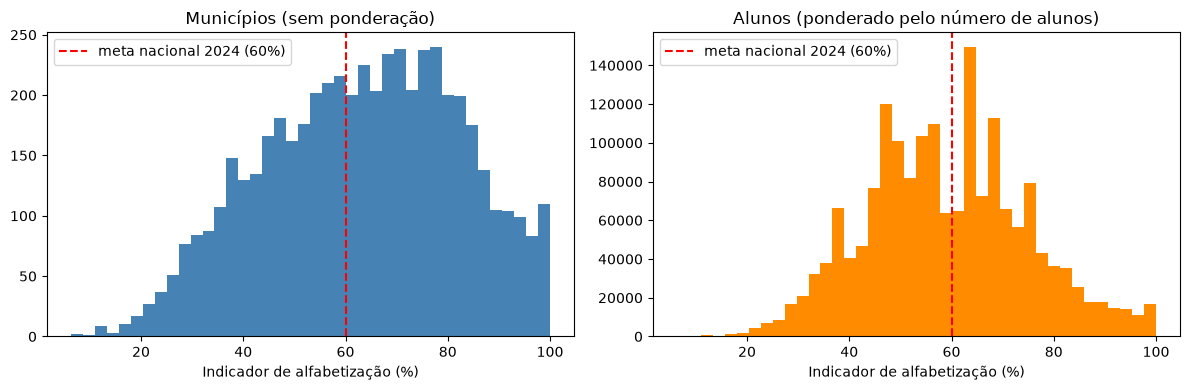

In [2]:
qs = [0.10, 0.25, 0.50, 0.75, 0.90]
resumo = pd.DataFrame(
    {
        "sem_ponderacao": [y.mean(), *np.quantile(y, qs)],
        "ponderado_por_alunos": [media_ponderada(y, w), *quantil_ponderado(y, w, qs)],
    },
    index=["média", "p10", "p25", "p50", "p75", "p90"],
)
print(resumo.round(2).to_string())

print(f"\n% de municípios com indicador >= 60:             {(y >= 60).mean():.1%}")
print(f"% de alunos em municípios com indicador >= 60:   {np.average(y >= 60, weights=w):.1%}")
print(f"% de municípios que atingiram a meta municipal:  {base['atingiu_meta'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=40, color="steelblue")
axes[0].set_title("Municípios (sem ponderação)")
axes[1].hist(y, bins=40, weights=w, color="darkorange")
axes[1].set_title("Alunos (ponderado pelo número de alunos)")
for ax in axes:
    ax.axvline(60, ls="--", c="red", label="meta nacional 2024 (60%)")
    ax.set_xlabel("Indicador de alfabetização (%)")
    ax.legend()
salvar_fig("01_distribuicao_alvo")

## 2. Tamanho do município × dispersão

Se parte da variação entre municípios pequenos for ruído amostral, a dispersão do indicador deve crescer à medida que o número de alunos cai, formando um "funil". As linhas tracejadas mostram o intervalo de 95% esperado **apenas pela variação amostral** em torno da média nacional ponderada.

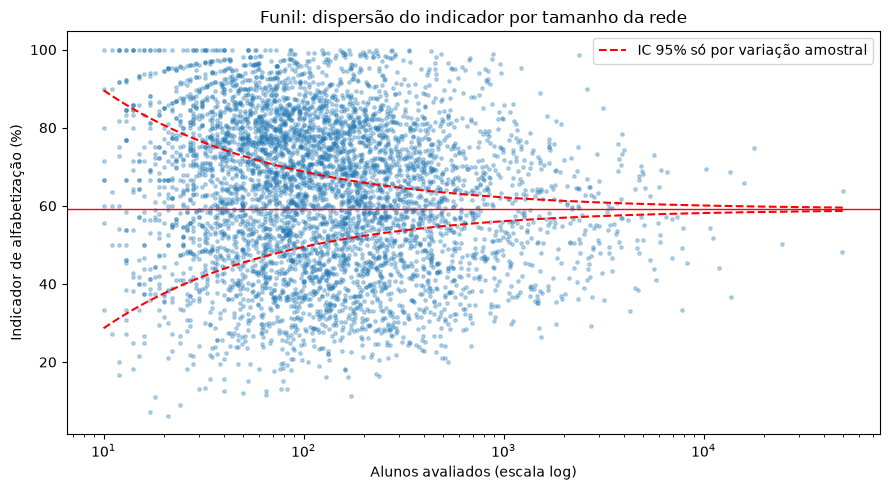

              municipios  alunos_min  alunos_max  dp_observado  dp_amostral_tipico  pct_variancia_ruido_aprox
quintil                                                                                                      
Q1 (menores)        1077          10          48         20.66                7.69                      13.85
Q2                  1016          49          86         19.41                5.47                       7.93
Q3                  1047          87         156         19.33                4.18                       4.69
Q4                  1046         157         324         18.68                3.07                       2.70
Q5 (maiores)        1046         325       49820         16.57                1.82                       1.20


In [3]:
p_nacional = media_ponderada(y, w) / 100
n_grade = np.logspace(np.log10(w.min()), np.log10(w.max()), 200)
banda = 1.96 * np.sqrt(p_nacional * (1 - p_nacional) / n_grade) * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(w, y, s=6, alpha=0.3)
ax.axhline(100 * p_nacional, c="red", lw=1)
ax.plot(n_grade, 100 * p_nacional + banda, "r--", label="IC 95% só por variação amostral")
ax.plot(n_grade, 100 * p_nacional - banda, "r--")
ax.set_xscale("log")
ax.set_xlabel("Alunos avaliados (escala log)")
ax.set_ylabel("Indicador de alfabetização (%)")
ax.set_title("Funil: dispersão do indicador por tamanho da rede")
ax.legend()
salvar_fig("02_funil_tamanho")

p_mun = y / 100
dp_amostral = 100 * np.sqrt(p_mun * (1 - p_mun) / w)

tabela = (
    base.assign(
        quintil=pd.qcut(w, 5, labels=["Q1 (menores)", "Q2", "Q3", "Q4", "Q5 (maiores)"]),
        dp_amostral=dp_amostral,
    )
    .groupby("quintil", observed=True)
    .agg(
        municipios=("id_municipio", "size"),
        alunos_min=("n_alunos", "min"),
        alunos_max=("n_alunos", "max"),
        dp_observado=("indicador_alfabetizacao", "std"),
        dp_amostral_tipico=("dp_amostral", "median"),
    )
)
tabela["pct_variancia_ruido_aprox"] = 100 * tabela["dp_amostral_tipico"] ** 2 / tabela["dp_observado"] ** 2
print(tabela.round(2).to_string())

## 3. Padrões de nulos

Hipótese: os nulos de `ce_alunos_turma_multietapa` e das colunas de creche são estruturais (o município não oferece a modalidade), não lacunas aleatórias. Se for o caso, os grupos "nulo" e "preenchido" devem diferir sistematicamente em porte e região.

In [4]:
comparar = ["n_alunos", "soc_populacao", "soc_densidade", "indicador_alfabetizacao"]

for coluna in ["ce_alunos_turma_multietapa", "ce_alunos_turma_creche"]:
    grupo = np.where(base[coluna].isna(), "nulo", "preenchido")
    tab = base.assign(grupo=grupo).groupby("grupo").agg(
        municipios=("id_municipio", "size"),
        **{f"mediana_{c}": (c, "median") for c in comparar},
    )
    print(f"=== {coluna}")
    print(tab.round(1).to_string())

    por_regiao = pd.crosstab(base["ter_regiao"], grupo, normalize="index").mul(100).round(1)
    print("\n% de municípios por região:")
    print(por_regiao.to_string())
    print()

=== ce_alunos_turma_multietapa
            municipios  mediana_n_alunos  mediana_soc_populacao  mediana_soc_densidade  mediana_indicador_alfabetizacao
grupo                                                                                                                  
nulo              2223              80.0                 7051.0                   25.3                             69.2
preenchido        3009             145.0                14589.0                   24.1                             59.8

% de municípios por região:
col_0         nulo  preenchido
ter_regiao                    
Centro-Oeste  57.7        42.3
Nordeste      14.7        85.3
Norte         22.1        77.9
Sudeste       57.9        42.1
Sul           65.9        34.1

=== ce_alunos_turma_creche
            municipios  mediana_n_alunos  mediana_soc_populacao  mediana_soc_densidade  mediana_indicador_alfabetizacao
grupo                                                                                          

## 4. Relação das features com o alvo

Correlação de Spearman (baseada em postos): robusta a assimetria e a outliers, e captura relações monotônicas não lineares — adequada para variáveis como população e investimento por aluno, muito assimétricas.

In [5]:
numericas = [c for c in base.columns if c.startswith(("ce_", "soc_", "fin_"))]
descricao = dicionario.set_index("coluna")["descricao"]

rho = base[numericas].corrwith(y, method="spearman")
tab_rho = pd.DataFrame({
    "familia": [c.split("_")[0] for c in numericas],
    "rho": rho,
    "n_validos": base[numericas].notna().sum(),
    "descricao": descricao.reindex(numericas).str.slice(0, 70),
}, index=numericas)
tab_rho = tab_rho.reindex(tab_rho["rho"].abs().sort_values(ascending=False).index)

print(tab_rho.round(3).to_string())
print("\nMaior |rho| por família:")
print(tab_rho.groupby("familia")["rho"].agg(lambda s: s.abs().max()).round(3).to_string())

                                   familia    rho  n_validos                                                               descricao
ce_aprovacao_anos_iniciais              ce  0.428       5229                                       Taxa de aprovação — anos iniciais
ce_reprovacao_anos_iniciais             ce -0.411       5229                                      Taxa de reprovação — anos iniciais
ce_distorcao_anos_iniciais              ce -0.408       5232                           Taxa de distorção idade-série — anos iniciais
ce_abandono_anos_iniciais               ce -0.407       5229                                        Taxa de abandono — anos iniciais
ce_adeq_docente_anos_iniciais_g5        ce -0.254       5228       % de docentes no grupo 5 de adequação da formação — anos iniciais
soc_idade_mediana                      soc  0.253       5232                                              Idade mediana da população
ce_docentes_superior_anos_iniciais      ce  0.252       5232         

## 5. Colinearidade entre features

Pares com |rho| >= 0,85 indicam redundância: para modelos lineares, inflam a variância dos coeficientes; para a interpretação (SHAP), dividem o crédito entre si.

Pares com |rho| >= 0,85: 16
                       feature_a                          feature_b    rho
      ce_aprovacao_anos_iniciais        ce_reprovacao_anos_iniciais -0.989
     ce_adeq_docente_infantil_g5      ce_docentes_superior_infantil -0.987
ce_adeq_docente_anos_iniciais_g5 ce_docentes_superior_anos_iniciais -0.979
               soc_idade_mediana          soc_indice_envelhecimento  0.956
               soc_alfab_15_mais                    soc_alfab_25_44  0.952
     ce_horas_aula_anos_iniciais                 ce_horas_aula_2ano  0.949
              ce_horas_aula_1ano                 ce_horas_aula_2ano  0.920
     ce_horas_aula_anos_iniciais                 ce_horas_aula_1ano  0.916
          ce_horas_aula_infantil               ce_horas_aula_creche  0.902
   ce_docentes_superior_infantil        ce_docentes_superior_creche  0.894
     ce_adeq_docente_infantil_g5        ce_docentes_superior_creche -0.883
     ce_adeq_docente_infantil_g5    ce_docentes_superior_pre_escola -0.8

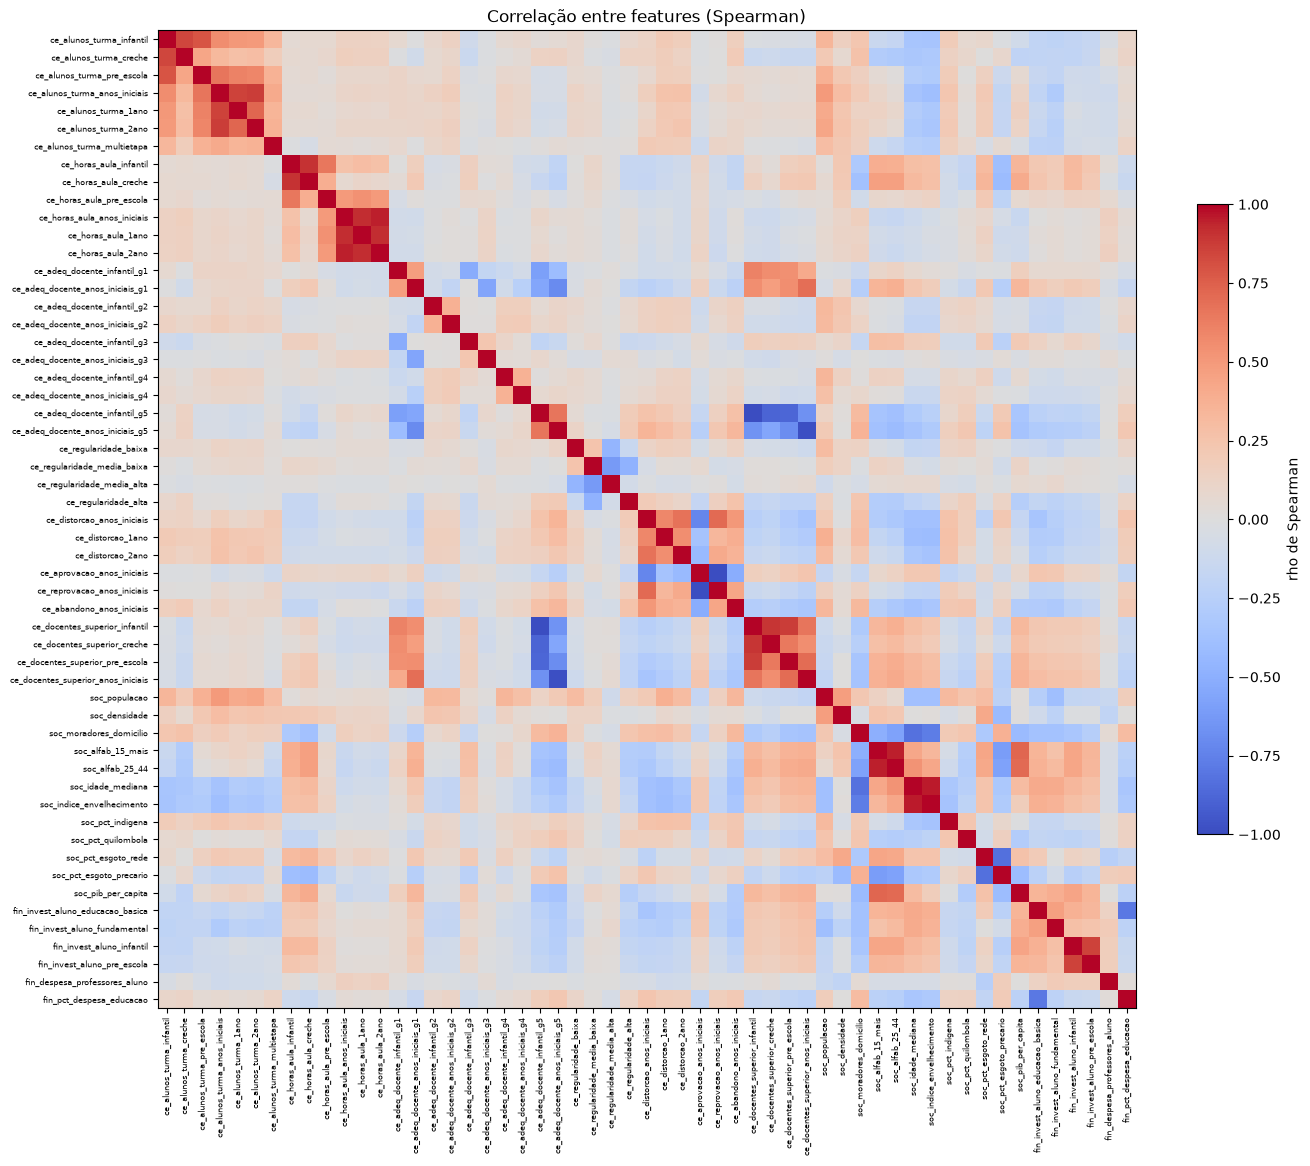

In [6]:
corr = base[numericas].corr(method="spearman")

triangulo = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(triangulo).stack().rename("rho").reset_index()
pares.columns = ["feature_a", "feature_b", "rho"]
pares = pares[pares["rho"].abs() >= 0.85].sort_values("rho", key=abs, ascending=False)
print(f"Pares com |rho| >= 0,85: {len(pares)}")
print(pares.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)))
ax.set_xticklabels(numericas, rotation=90, fontsize=6)
ax.set_yticks(range(len(numericas)))
ax.set_yticklabels(numericas, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.6, label="rho de Spearman")
ax.set_title("Correlação entre features (Spearman)")
salvar_fig("03_correlacao_features")

## 6. Recorte regional ponderado

Médias simples (cada município pesa igual) versus ponderadas pelo número de alunos. Substitui o recorte da EDA anterior, que usava uma amostra com linhas duplicadas da Silver e médias não ponderadas.

In [7]:
def resumo_grupo(g: pd.DataFrame) -> pd.Series:
    indicador = g["indicador_alfabetizacao"].astype(float)
    alunos = g["n_alunos"].astype(float)
    return pd.Series({
        "municipios": len(g),
        "alunos": alunos.sum(),
        "media_simples": indicador.mean(),
        "media_ponderada": np.average(indicador, weights=alunos),
        "pct_municipios_60": 100 * (indicador >= 60).mean(),
    })


por_regiao = base.groupby("ter_regiao").apply(resumo_grupo).sort_values("media_ponderada")
print("=== Por região")
print(por_regiao.round(1).to_string())

por_uf = base.groupby("ter_uf").apply(resumo_grupo).sort_values("media_ponderada")
print("\n=== Por UF")
print(por_uf.round(1).to_string())

=== Por região
              municipios    alunos  media_simples  media_ponderada  pct_municipios_60
ter_regiao                                                                           
Norte              389.0  178874.0           50.2             50.0               25.4
Nordeste          1738.0  485959.0           56.8             56.5               40.2
Sudeste           1590.0  690991.0           70.0             60.2               75.0
Sul               1054.0  253695.0           64.7             63.5               63.8
Centro-Oeste       461.0  166917.0           72.3             65.2               78.1

=== Por UF
        municipios    alunos  media_simples  media_ponderada  pct_municipios_60
ter_uf                                                                         
BA           394.0  113789.0           36.6             35.9                2.5
SE            75.0   17102.0           36.4             38.0                4.0
RN           139.0   18309.0           42.8        

## Conclusões e decisões de modelagem

**Alvo**
- A média ponderada pelo número de alunos (59,1%) reproduz a taxa nacional oficial de 2024 (59,2%), validando alvo e pesos.
- Unidade de análise importa: 57,8% dos municípios estão acima de 60%, mas apenas 47,2% dos alunos.
- **Decisão (D5):** classificação no nível do aluno — cada município expandido em alfabetizados (1) e não alfabetizados (0), com pesos iguais às contagens; validação cruzada agrupada por município; desempenho reportado em relação ao teto (AUC do oráculo que conhece a taxa real de cada município). Visão complementar por município: taxa prevista < 60% = em risco.

**Ruído amostral**
- O funil confirma maior dispersão nos municípios pequenos, mas o ruído amostral explica ~14% da variância no quintil menor e 1–5% nos demais: a maior parte da variação é estrutural (há sinal a aprender). A ponderação por alunos reduz a influência do ruído sem descartar municípios.

**Nulos**
- Estruturais: turmas multietapa (42%) e creche (~3%) — ausência da modalidade. Os nulos de multietapa concentram-se no Sul/Sudeste/Centro-Oeste e em municípios menores: a flag de ausência carrega sinal de organização regional da rede. Tratamento: imputação + indicador de ausência no pipeline.
- Esporádicos (1 a 5 municípios): imputação simples no pipeline.

**Relação com o alvo**
- Fluxo escolar (aprovação, reprovação, abandono, distorção) domina (|ρ| ≈ 0,41–0,43) — família no limite entre contexto e histórico de desempenho. **Ablação obrigatória** com e sem essa família.
- Socioeconômicas com relação monotônica fraca (PIB 0,11; esgoto 0,08; alfabetização 15+ 0,12; geração dos pais 0,18).
- % do orçamento em educação com sinal negativo: provável efeito de composição orçamentária em municípios pobres — correlação não é causa.

**Colinearidade — lista curada de 44 features** (base preservada; corte na configuração da modelagem)
- Retiradas: `ce_reprovacao_anos_iniciais`, `ce_docentes_superior_*` (4), `ce_horas_aula_1ano`, `ce_horas_aula_2ano`, `ce_horas_aula_creche`, `ce_alunos_turma_1ano`, `ce_alunos_turma_2ano`, `soc_indice_envelhecimento`, `soc_alfab_15_mais`, `fin_invest_aluno_infantil`.
- Grupos composicionais (adequação docente g1–g5, regularidade em 4 faixas): completos nas árvores; menos uma coluna por grupo no modelo linear.

**Território**
- Médias ponderadas por região: Norte 50,0; Nordeste 56,5; Sudeste 60,2; Sul 63,5; Centro-Oeste 65,2 (corrige a EDA anterior).
- A variação entre UFs supera a entre regiões: Bahia 35,9% e Ceará 85,3%, ambas no Nordeste. Rio Grande do Sul (46,1%) destoa do Sul — hipótese: enchentes de maio de 2024 (choque não medido pelas features).
- O efeito de UF mistura política educacional estadual e diferenças de instrumento (o indicador alinha avaliações estaduais distintas à escala do Saeb). **Ablação** com e sem a família `ter_`.